---
## STEP 1 — Import Libraries

Before we do anything, we load all the tools we need.

Think of this like setting up your workbench before starting a job — you gather all your tools first so you're not stopping mid-way to find something.

| Library | What it does |
|---|---|
| `pandas` | Loads and manipulates data in table format |
| `numpy` | Fast math operations on arrays |
| `matplotlib / seaborn` | Draws charts and visualizations |
| `scikit-learn` | Builds and evaluates ML models |
| `statsmodels` | Statistical analysis — gives us p-values and confidence intervals |
| `joblib` | Saves our trained model to disk |

In [1]:
# Core
import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, accuracy_score, precision_score, recall_score, f1_score
)

# Stats
import statsmodels.api as sm

# Save model
import joblib

print('✅ All libraries imported successfully')

C:\Users\Hamsa\AppData\Local\Temp\ipykernel_17988\2347718215.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


✅ All libraries imported successfully


---
## STEP 2 — Set File Paths

Instead of hardcoding paths everywhere, we define them once here.

**Why this matters:** If you move the project to a different folder or share it with someone else, you only need to update one place instead of hunting through every cell.

In [3]:
# Update this to match where your project folder is located
BASE = r"C:\Users\Hamsa\OneDrive\Desktop\customer-churn-prediction-main"

DATA_PATH   = os.path.join(BASE, 'data', 'WA_Fn-UseC_-Telco-Customer-Churn.csv')
OUTPUT_PATH = os.path.join(BASE, 'outputs')
MODEL_PATH  = os.path.join(BASE, 'models')

# Create folders if they don't exist
os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(MODEL_PATH, exist_ok=True)

print(f'Data   : {DATA_PATH}')
print(f'Outputs: {OUTPUT_PATH}')
print(f'Models : {MODEL_PATH}')

Data   : C:\Users\Hamsa\OneDrive\Desktop\customer-churn-prediction-main\data\WA_Fn-UseC_-Telco-Customer-Churn.csv
Outputs: C:\Users\Hamsa\OneDrive\Desktop\customer-churn-prediction-main\outputs
Models : C:\Users\Hamsa\OneDrive\Desktop\customer-churn-prediction-main\models


---
## STEP 3 — Load the Dataset

We are using the **IBM Telco Customer Churn dataset** — a real-world dataset containing 7,043 telecom customers with 21 features including:
- Customer demographics (gender, age, dependents)
- Services subscribed (internet, phone, streaming)
- Account information (contract type, payment method, charges)
- **Target variable:** whether the customer churned (Yes/No)

Download it from: kaggle.com/datasets/blastchar/telco-customer-churn

In [4]:
df = pd.read_csv(DATA_PATH)

print(f'Rows    : {df.shape[0]}')
print(f'Columns : {df.shape[1]}')
print(f'\nColumn names:')
print(df.columns.tolist())

df.head()

Rows    : 7043
Columns : 21

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


---
## STEP 4 — Understand the Data

Before building any model, we need to understand what we're working with.

Key questions to answer:
- How many customers churned vs stayed?
- Are there missing values?
- What data types do we have?

**Why churn rate matters:** If only 1% of customers churn, a model that predicts 'No Churn' for everyone will be 99% accurate — but completely useless. We call this the **class imbalance problem**.

In [5]:
print('=== Data Types ===')
print(df.dtypes)

print('\n=== Missing Values ===')
print(df.isnull().sum()[df.isnull().sum() > 0])

print('\n=== Churn Distribution ===')
print(df['Churn'].value_counts())
churn_rate = (df['Churn'] == 'Yes').mean()
print(f'\nChurn Rate: {churn_rate:.1%}')
print('\n💡 Note: ~26% churn rate means our dataset is imbalanced but manageable.')

=== Data Types ===
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

=== Missing Values ===
Series([], dtype: int64)

=== Churn Distribution ===
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Rate: 26.5%

💡 Note: ~26% churn rate means our dataset is imbalanced but manageable.


---
## STEP 5 — Exploratory Data Analysis (EDA)

EDA is how we let the data tell us its story before we start modeling.

We are looking for:
- Which features are strongly associated with churn?
- Are there patterns in customer behavior?
- What does a typical churning customer look like?

**Rule of thumb:** Good EDA means you already have a hypothesis about what the model will find before you build it.

In [6]:
# --- 5.1 Churn Distribution ---
fig, axes = plt.subplots(1, 2)

churn_counts = df['Churn'].value_counts()
axes[0].pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%',
            colors=['#4CAF50', '#F44336'], startangle=90)
axes[0].set_title('Churn Distribution', fontweight='bold')

sns.countplot(data=df, x='Churn', palette=['#4CAF50', '#F44336'], ax=axes[1])
axes[1].set_title('Churn Count', fontweight='bold')

plt.suptitle('Customer Churn Overview', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'churn_distribution.png'), dpi=150)
plt.show()

print('💡 About 1 in 4 customers churned — this is our target to predict.')

<Figure size 1200x500 with 2 Axes>

💡 About 1 in 4 customers churned — this is our target to predict.


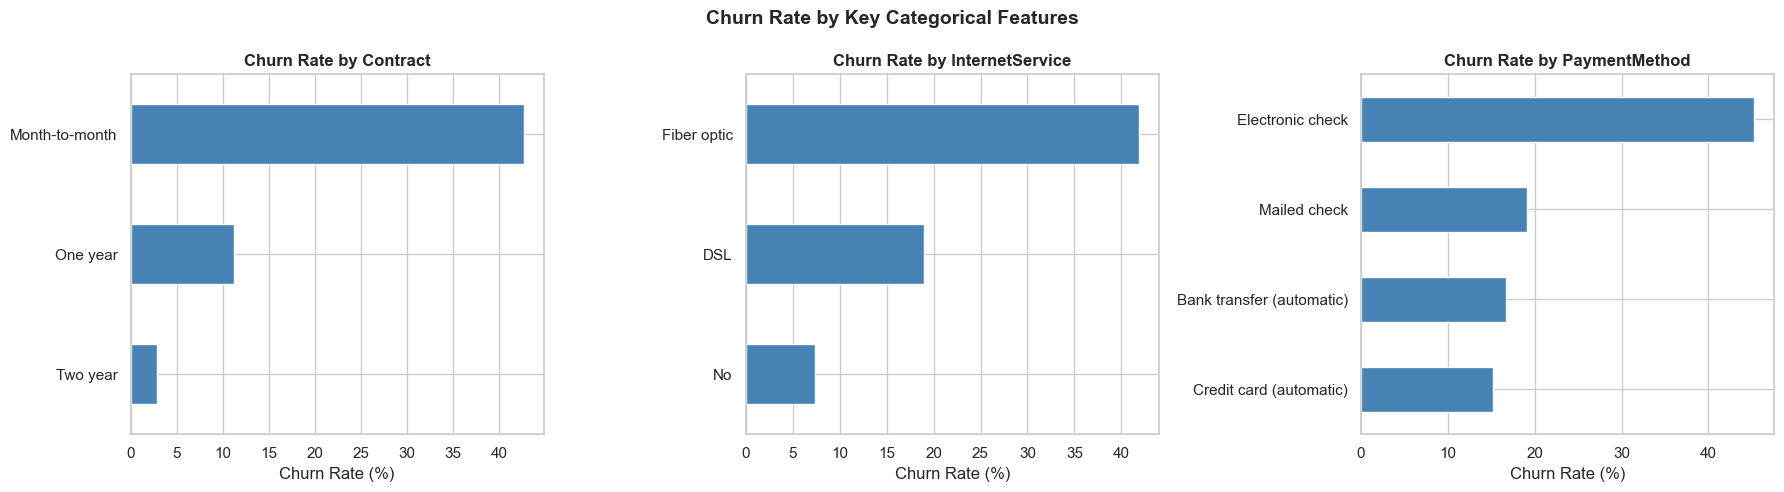

💡 Month-to-month customers churn far more than annual contract customers.
💡 Electronic check payment method has the highest churn rate.


In [7]:
# --- 5.2 Churn by Contract, Internet Service, Payment Method ---
# These are the features most business people would guess matter
# Let's verify with data

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ['Contract', 'InternetService', 'PaymentMethod']):
    churn_rate = df.groupby(col)['Churn'].apply(lambda x: (x=='Yes').mean() * 100)
    churn_rate.sort_values().plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(f'Churn Rate by {col}', fontweight='bold')
    ax.set_xlabel('Churn Rate (%)')
    ax.set_ylabel('')

plt.suptitle('Churn Rate by Key Categorical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'churn_by_category.png'), dpi=150)
plt.show()

print('💡 Month-to-month customers churn far more than annual contract customers.')
print('💡 Electronic check payment method has the highest churn rate.')

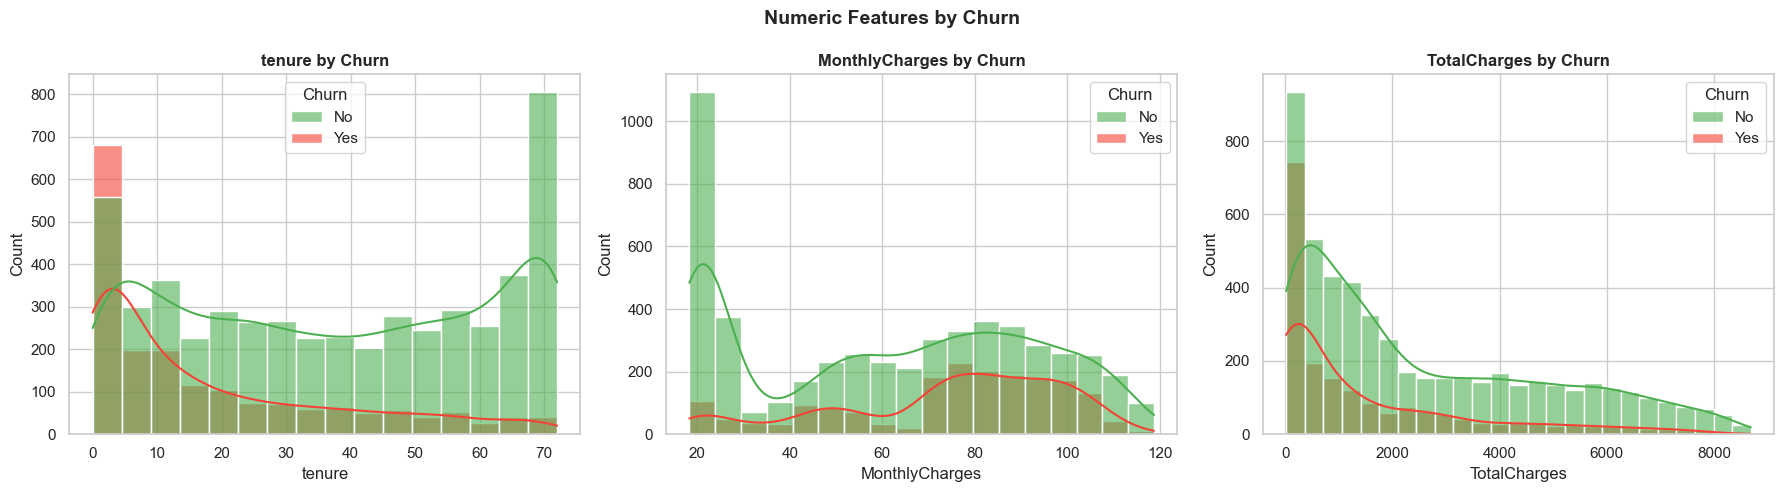

💡 Customers with LOW tenure (new customers) churn the most.
💡 Customers with HIGH monthly charges churn more.
💡 This makes business sense — new customers havent built loyalty yet.


In [8]:
# --- 5.3 Numeric Features by Churn ---
# tenure = how long the customer has been with the company (months)
# MonthlyCharges = what they pay per month
# TotalCharges = total amount paid since joining

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    df_plot = df.copy()
    df_plot[col] = pd.to_numeric(df_plot[col], errors='coerce')
    sns.histplot(data=df_plot, x=col, hue='Churn', kde=True,
                 palette=['#4CAF50', '#F44336'], ax=ax, alpha=0.6)
    ax.set_title(f'{col} by Churn', fontweight='bold')

plt.suptitle('Numeric Features by Churn', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'numeric_distributions.png'), dpi=150)
plt.show()

print('💡 Customers with LOW tenure (new customers) churn the most.')
print('💡 Customers with HIGH monthly charges churn more.')
print('💡 This makes business sense — new customers havent built loyalty yet.')

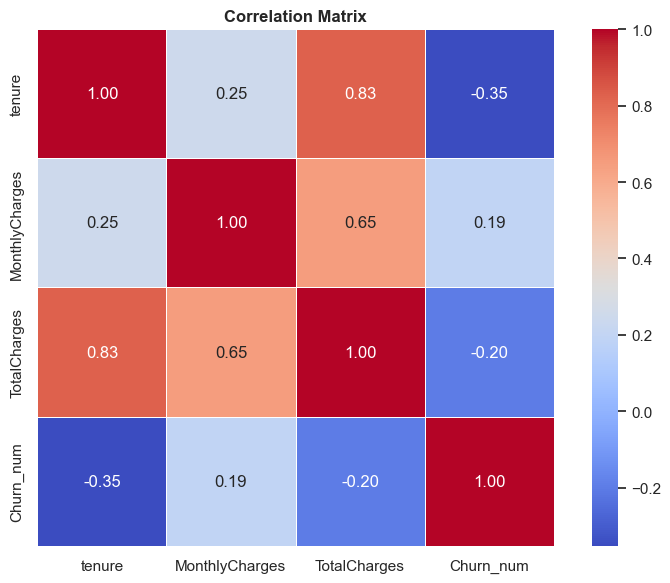

💡 tenure has NEGATIVE correlation with churn (-0.35) — longer customers churn less.
💡 MonthlyCharges has POSITIVE correlation with churn (+0.19) — higher charges = more churn.


In [9]:
# --- 5.4 Correlation Heatmap ---
# Correlation tells us how strongly two numeric variables move together
# Values range from -1 (opposite) to +1 (same direction)
# We want to find which numeric features correlate with churn

df_corr = df.copy()
df_corr['TotalCharges'] = pd.to_numeric(df_corr['TotalCharges'], errors='coerce')
df_corr['Churn_num'] = (df_corr['Churn'] == 'Yes').astype(int)

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_num']
corr_matrix = df_corr[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            square=True, linewidths=0.5)
plt.title('Correlation Matrix', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'correlation_heatmap.png'), dpi=150)
plt.show()

print('💡 tenure has NEGATIVE correlation with churn (-0.35) — longer customers churn less.')
print('💡 MonthlyCharges has POSITIVE correlation with churn (+0.19) — higher charges = more churn.')

---
## STEP 6 — Data Cleaning

Raw data is never perfect. Before modeling, we need to fix issues.

Issues we found in EDA:
1. `TotalCharges` is stored as a string (object) — should be numeric
2. `TotalCharges` has 11 missing values — new customers with no charges yet
3. `customerID` is just an ID — not useful for prediction
4. `Churn` is Yes/No — needs to be 1/0 for the model

**Key principle:** Never fill missing values blindly. Always think about WHY they are missing — that context tells you HOW to fill them.

In [10]:
df_clean = df.copy()

# Drop customerID — it's just an identifier, not a predictor
df_clean.drop('customerID', axis=1, inplace=True)
print('✅ Dropped customerID')

# Fix TotalCharges — convert from string to float
# Empty strings become NaN automatically
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
print(f'✅ TotalCharges converted — missing values: {df_clean["TotalCharges"].isnull().sum()}')

# Fill missing TotalCharges with median
# These are new customers (tenure=0) so median is appropriate
median_charges = df_clean['TotalCharges'].median()
df_clean['TotalCharges'].fillna(median_charges, inplace=True)
print(f'✅ Missing TotalCharges filled with median: £{median_charges:.2f}')

# Encode target: Yes=1, No=0
df_clean['Churn'] = (df_clean['Churn'] == 'Yes').astype(int)
print(f'✅ Churn encoded: {df_clean["Churn"].value_counts().to_dict()}')

# Encode simple Yes/No binary columns
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for col in binary_cols:
    df_clean[col] = (df_clean[col] == 'Yes').astype(int)
print(f'✅ Binary columns encoded: {binary_cols}')

print(f'\nFinal shape: {df_clean.shape}')
print(f'Missing values remaining: {df_clean.isnull().sum().sum()}')

✅ Dropped customerID
✅ TotalCharges converted — missing values: 11
✅ Missing TotalCharges filled with median: £1397.47
✅ Churn encoded: {0: 5174, 1: 1869}
✅ Binary columns encoded: ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']

Final shape: (7043, 20)
Missing values remaining: 0


---
## STEP 7 — Feature Engineering

Feature engineering is the process of creating **new, more informative features** from existing ones.

This is one of the most impactful things you can do in an ML project — a well-engineered feature often matters more than which model you pick.

**Features we'll create:**
1. `AvgMonthlySpend` — how much a customer spends per month on average (TotalCharges / tenure)
2. `TenureGroup` — segments customers by loyalty stage (new, growing, mature, loyal)

**Why these?** They capture relationships that raw features don't express clearly. A customer who spent £500 total over 1 month is very different from one who spent £500 over 10 months.

In [11]:
# One-hot encode remaining categorical columns
# This converts categories like 'Fiber optic', 'DSL', 'No' into separate 0/1 columns
# drop_first=True avoids the dummy variable trap (multicollinearity)

cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
print(f'Categorical columns being encoded: {cat_cols}')

df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)
print(f'\nShape before encoding: {df_clean.shape}')
print(f'Shape after encoding : {df_encoded.shape}')
print('\n💡 Each category became its own 0/1 column — the model can now read them.')

Categorical columns being encoded: ['gender', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']

Shape before encoding: (7043, 20)
Shape after encoding : (7043, 31)

💡 Each category became its own 0/1 column — the model can now read them.


In [12]:
# Create new engineered features

# Feature 1: Average monthly spend
# +1 avoids division by zero for customers with tenure=0
df_encoded['AvgMonthlySpend'] = df_encoded['TotalCharges'] / (df_encoded['tenure'] + 1)

# Feature 2: Tenure group — loyalty stage segmentation
# 1 = New (0-12 months), 2 = Growing (1-2 years),
# 3 = Mature (2-4 years), 4 = Loyal (4+ years)
df_encoded['TenureGroup'] = pd.cut(
    df_encoded['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=[1, 2, 3, 4]
).astype(int)

print('✅ New features created:')
print(f'  AvgMonthlySpend — sample values: {df_encoded["AvgMonthlySpend"].head(3).round(2).tolist()}')
print(f'  TenureGroup     — distribution:\n{df_encoded["TenureGroup"].value_counts().sort_index()}')
print(f'\nTotal features now: {df_encoded.shape[1] - 1}')

✅ New features created:
  AvgMonthlySpend — sample values: [14.92, 53.99, 36.05]
  TenureGroup     — distribution:
TenureGroup
1    2186
2    1024
3    1594
4    2239
Name: count, dtype: int64

Total features now: 32


---
## STEP 8 — Train/Test Split

We split our data into two sets:
- **Training set (80%):** The model learns from this
- **Test set (20%):** We evaluate the model on data it has never seen

**Why not train on everything?**
If you test on the same data you trained on, the model looks great — but it has just memorized the data, not learned patterns. This is called **overfitting**. The test set simulates real-world performance.

**Why stratified split?**
We use `stratify=y` to make sure both train and test sets have the same churn ratio (~26%). Without this, you might accidentally put most churners in one set.

In [13]:
X = df_encoded.drop('Churn', axis=1)   # features
y = df_encoded['Churn']                 # target

# Stratified split — preserves churn ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set   : {X_train.shape[0]} customers')
print(f'Test set       : {X_test.shape[0]} customers')
print(f'Features       : {X_train.shape[1]}')
print(f'\nChurn rate — train : {y_train.mean():.1%}')
print(f'Churn rate — test  : {y_test.mean():.1%}')
print('\n💡 Both sets have ~26% churn — stratification worked correctly.')

# Fill NaNs immediately after split
X_train.loc[:, "TotalCharges"] = X_train["TotalCharges"].fillna(X_train["TotalCharges"].median())
X_test.loc[:, "TotalCharges"] = X_test["TotalCharges"].fillna(X_train["TotalCharges"].median())

X_train.loc[:, "AvgMonthlySpend"] = X_train["AvgMonthlySpend"].fillna(X_train["AvgMonthlySpend"].median())
X_test.loc[:, "AvgMonthlySpend"] = X_test["AvgMonthlySpend"].fillna(X_train["AvgMonthlySpend"].median())


Training set   : 5634 customers
Test set       : 1409 customers
Features       : 32

Churn rate — train : 26.5%
Churn rate — test  : 26.5%

💡 Both sets have ~26% churn — stratification worked correctly.


In [14]:
# Scale numeric features
# StandardScaler transforms values to have mean=0 and std=1
# WHY: Logistic Regression is sensitive to feature scale.
# A feature ranging 0-72 (tenure) would dominate one ranging 0-1 without scaling.
# Note: We fit the scaler on TRAINING data only, then apply to test.
# Fitting on test data would be data leakage.

scaler = StandardScaler()
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlySpend']

X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])  # fit + transform
X_test[numeric_features]  = scaler.transform(X_test[numeric_features])        # transform only

print('✅ Numeric features scaled')
print(f'\nExample — tenure mean after scaling: {X_train["tenure"].mean():.4f} (should be ~0)')
print(f'Example — tenure std after scaling : {X_train["tenure"].std():.4f} (should be ~1)')

✅ Numeric features scaled

Example — tenure mean after scaling: -0.0000 (should be ~0)
Example — tenure std after scaling : 1.0001 (should be ~1)


---
## STEP 9 — Logistic Regression (Baseline Model)

We always start with the simplest model first — this is called a **baseline**.

**Why Logistic Regression first?**
- It's fast and interpretable — you can explain exactly why it made a prediction
- It gives you a performance floor — if your fancy model can't beat this, something is wrong
- It works surprisingly well on many real-world problems

**What it does:** Estimates the probability that a customer will churn (0 to 1), then classifies above 0.5 as churn.

In [15]:
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train, y_train)

lr_pred  = lr.predict(X_test)
lr_proba = lr.predict_proba(X_test)[:, 1]  # probability of churn

print('=== Logistic Regression Results ===')
print(f'Accuracy  : {accuracy_score(y_test, lr_pred):.4f}')
print(f'Precision : {precision_score(y_test, lr_pred):.4f}')
print(f'Recall    : {recall_score(y_test, lr_pred):.4f}')
print(f'F1 Score  : {f1_score(y_test, lr_pred):.4f}')
print(f'ROC-AUC   : {roc_auc_score(y_test, lr_proba):.4f}')

=== Logistic Regression Results ===
Accuracy  : 0.8105
Precision : 0.6814
Recall    : 0.5374
F1 Score  : 0.6009
ROC-AUC   : 0.8470


### Understanding the Metrics

This is where most tutorials lose people. Let's make this clear with a business lens:

| Metric | What it asks | Business meaning |
|---|---|---|
| **Accuracy** | Of all predictions, how many were right? | Misleading for imbalanced data |
| **Precision** | Of customers we flagged as churners, how many actually churned? | How many false alarms are we sending? |
| **Recall** | Of all actual churners, how many did we catch? | How many churners are we missing? |
| **F1 Score** | Balance between Precision and Recall | Overall model quality |
| **ROC-AUC** | How well can the model rank churners vs non-churners? | Best single metric for churn models |

**For churn prediction, Recall matters more than Precision.**
Missing a churner (False Negative) costs more than a false alarm (False Positive). It's better to offer a retention discount to someone who wasn't going to leave than to miss someone who was.

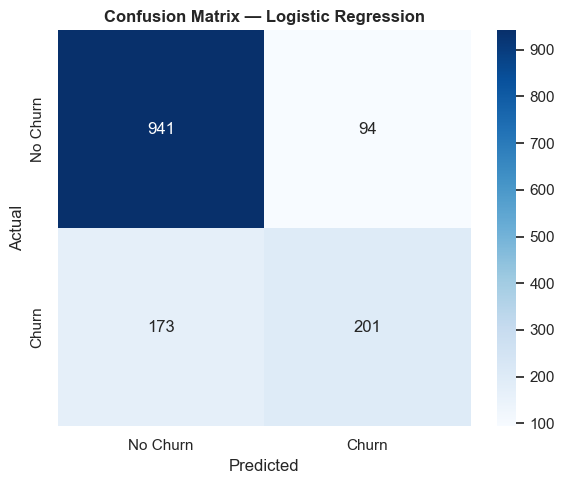

True Positives  (caught churners)    : 201
False Negatives (missed churners)    : 173  ← these cost us the most
False Positives (false alarms)       : 94
True Negatives  (correct stays)      : 941


In [16]:
# Confusion Matrix — visualizes what the model got right and wrong
#
# True Negative  | False Positive  (predicted churn, actually stayed)
# False Negative | True Positive   (predicted stay, actually churned)
#
# False Negatives are our most costly error — we missed real churners

cm = confusion_matrix(y_test, lr_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.title('Confusion Matrix — Logistic Regression', fontweight='bold')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'confusion_matrix_lr.png'), dpi=150)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'True Positives  (caught churners)    : {tp}')
print(f'False Negatives (missed churners)    : {fn}  ← these cost us the most')
print(f'False Positives (false alarms)       : {fp}')
print(f'True Negatives  (correct stays)      : {tn}')

---
## STEP 10 — Advanced Models

Now we try more powerful models and see if they beat our baseline.

**Random Forest:**
Builds many decision trees and combines their votes. More robust than a single tree because individual trees overfit, but averaged together they generalize better. This is called **ensemble learning**.

**Gradient Boosting:**
Builds trees sequentially — each new tree focuses on fixing the mistakes of the previous one. Generally more accurate than Random Forest but slower to train.

In [17]:
# Random Forest
# n_estimators=100 means 100 trees — more trees = more stable but slower
# n_jobs=-1 means use all CPU cores to speed up training

print('Training Random Forest...')
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_pred  = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

print('=== Random Forest Results ===')
print(f'Accuracy  : {accuracy_score(y_test, rf_pred):.4f}')
print(f'Precision : {precision_score(y_test, rf_pred):.4f}')
print(f'Recall    : {recall_score(y_test, rf_pred):.4f}')
print(f'F1 Score  : {f1_score(y_test, rf_pred):.4f}')
print(f'ROC-AUC   : {roc_auc_score(y_test, rf_proba):.4f}')

Training Random Forest...
=== Random Forest Results ===
Accuracy  : 0.7835
Precision : 0.6219
Recall    : 0.4706
F1 Score  : 0.5358
ROC-AUC   : 0.8238


In [18]:
# Gradient Boosting
print('Training Gradient Boosting...')
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb.fit(X_train, y_train)

gb_pred  = gb.predict(X_test)
gb_proba = gb.predict_proba(X_test)[:, 1]

print('=== Gradient Boosting Results ===')
print(f'Accuracy  : {accuracy_score(y_test, gb_pred):.4f}')
print(f'Precision : {precision_score(y_test, gb_pred):.4f}')
print(f'Recall    : {recall_score(y_test, gb_pred):.4f}')
print(f'F1 Score  : {f1_score(y_test, gb_pred):.4f}')
print(f'ROC-AUC   : {roc_auc_score(y_test, gb_proba):.4f}')

Training Gradient Boosting...
=== Gradient Boosting Results ===
Accuracy  : 0.7970
Precision : 0.6486
Recall    : 0.5134
F1 Score  : 0.5731
ROC-AUC   : 0.8424


---
## STEP 11 — Model Comparison & ROC Curves

The **ROC Curve** plots True Positive Rate (Recall) vs False Positive Rate at different classification thresholds.

**How to read it:**
- The diagonal line = random guessing (AUC = 0.5)
- The further a curve bends toward the top-left = better model
- AUC of 0.85 means the model correctly ranks a churner above a non-churner 85% of the time

**AUC ranges:**
- 0.5 = no better than random
- 0.7–0.8 = acceptable
- 0.8–0.9 = good
- 0.9+ = excellent

In [19]:
# Model comparison table
results = pd.DataFrame({
    'Model'    : ['Logistic Regression', 'Random Forest', 'Gradient Boosting'],
    'Accuracy' : [accuracy_score(y_test, lr_pred), accuracy_score(y_test, rf_pred), accuracy_score(y_test, gb_pred)],
    'Precision': [precision_score(y_test, lr_pred), precision_score(y_test, rf_pred), precision_score(y_test, gb_pred)],
    'Recall'   : [recall_score(y_test, lr_pred), recall_score(y_test, rf_pred), recall_score(y_test, gb_pred)],
    'F1 Score' : [f1_score(y_test, lr_pred), f1_score(y_test, rf_pred), f1_score(y_test, gb_pred)],
    'ROC-AUC'  : [roc_auc_score(y_test, lr_proba), roc_auc_score(y_test, rf_proba), roc_auc_score(y_test, gb_proba)]
}).round(4).set_index('Model')

print('=== Model Comparison ===')
results

=== Model Comparison ===


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8105,0.6814,0.5374,0.6009,0.8470
Random Forest,0.7835,0.6219,0.4706,0.5358,0.8238
Gradient Boosting,0.7970,0.6486,0.5134,0.5731,0.8424


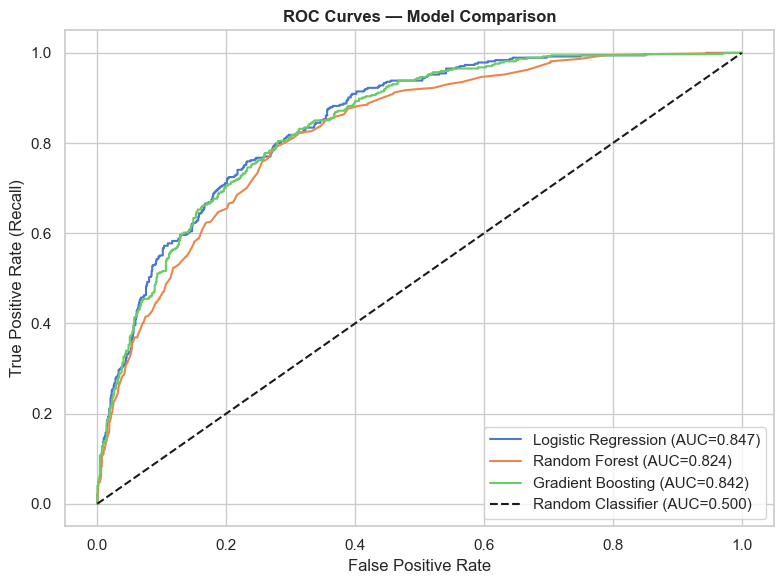

In [20]:
# ROC Curves
plt.figure(figsize=(8, 6))

for name, proba in [
    ('Logistic Regression', lr_proba),
    ('Random Forest',       rf_proba),
    ('Gradient Boosting',   gb_proba)
]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')

plt.plot([0,1], [0,1], 'k--', label='Random Classifier (AUC=0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves — Model Comparison', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'roc_curves.png'), dpi=150)
plt.show()

---
## STEP 12 — Feature Importance

Feature importance tells us **which features the model relied on most** when making predictions.

This is one of the most valuable outputs for business stakeholders — it answers the question: **"What actually drives churn in our customer base?"`**

We use Gradient Boosting's feature importance because it tends to be the most reliable of the three models.

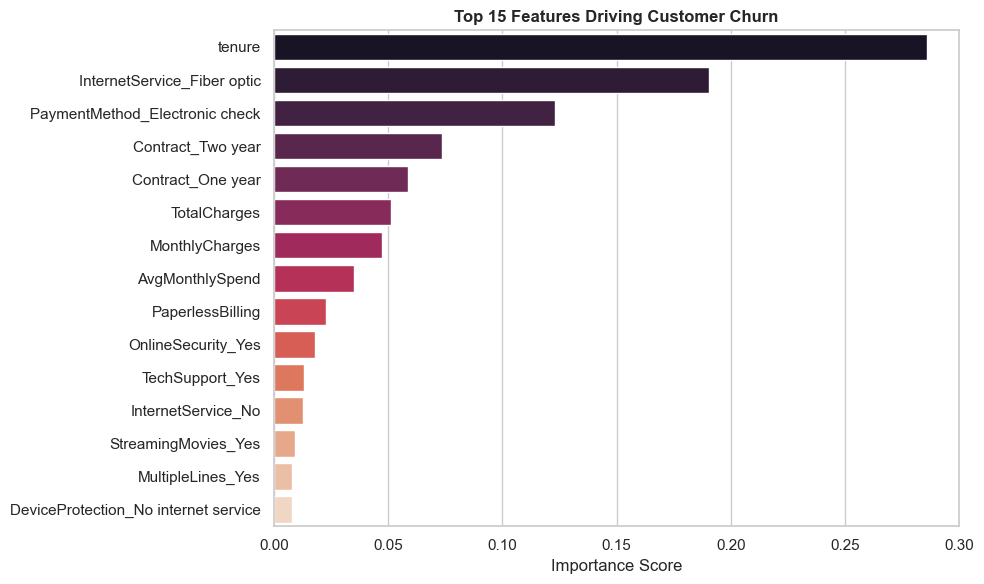

Top 5 churn drivers:
                           Feature  Importance
3                           tenure    0.285726
11     InternetService_Fiber optic    0.190671
28  PaymentMethod_Electronic check    0.123226
26               Contract_Two year    0.073338
25               Contract_One year    0.058747

💡 These are the levers the business should focus on to reduce churn.


In [21]:
feature_importance = pd.DataFrame({
    'Feature'   : X_train.columns,
    'Importance': gb.feature_importances_
}).sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='Importance', y='Feature', palette='rocket')
plt.title('Top 15 Features Driving Customer Churn', fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'feature_importance.png'), dpi=150)
plt.show()

print('Top 5 churn drivers:')
print(feature_importance.head().to_string())
print('\n💡 These are the levers the business should focus on to reduce churn.')

---
## STEP 13 — Statistical Inference with Statsmodels

Scikit-learn tells us **what** predicts churn. Statsmodels tells us **how confident we are** that it's real and not random.

Key outputs:
- **P-value:** Probability that a feature's effect is due to chance. P < 0.05 = statistically significant
- **Odds Ratio:** How much a feature multiplies the odds of churn. Odds ratio > 1 increases churn risk, < 1 decreases it
- **Coefficient:** Direction and strength of the relationship

This is what separates a data scientist from someone who just runs models — the ability to attach statistical confidence to findings.

In [22]:
# Use top features from importance analysis
top_features = feature_importance['Feature'].head(10).tolist()

# Statsmodels requires us to add a constant (intercept) manually
X_train_sm = sm.add_constant(X_train[top_features].astype(float))

logit_model  = sm.Logit(y_train.astype(float), X_train_sm)
logit_result = logit_model.fit(disp=0)

# Extract key stats
summary_df = pd.DataFrame({
    'Coefficient': logit_result.params,
    'P-Value'    : logit_result.pvalues,
    'Odds Ratio' : np.exp(logit_result.params)
}).round(4)

print('=== Statistically Significant Features (p < 0.05) ===')
sig = summary_df[summary_df['P-Value'] < 0.05].sort_values('P-Value')
print(sig)
print('\n💡 Odds Ratio > 1 = increases churn risk')
print('💡 Odds Ratio < 1 = decreases churn risk')

=== Statistically Significant Features (p < 0.05) ===
                                Coefficient  P-Value  Odds Ratio
const                               -1.5703   0.0000      0.2080
tenure                              -0.8177   0.0000      0.4414
PaymentMethod_Electronic check       0.4821   0.0000      1.6195
Contract_Two year                   -1.8116   0.0000      0.1634
Contract_One year                   -0.8812   0.0000      0.4143
MonthlyCharges                       1.4074   0.0000      4.0852
AvgMonthlySpend                     -2.1572   0.0000      0.1156
PaperlessBilling                     0.4617   0.0000      1.5867
OnlineSecurity_Yes                  -0.4540   0.0000      0.6351
InternetService_Fiber optic          0.4479   0.0017      1.5650
TotalCharges                         0.4105   0.0099      1.5075

💡 Odds Ratio > 1 = increases churn risk
💡 Odds Ratio < 1 = decreases churn risk


---
## STEP 14 — Customer Risk Segmentation

Instead of just predicting churn (Yes/No), we use the model's **probability scores** to segment customers into risk tiers.

This is far more useful for the business because different risk levels need different interventions:
- **High Risk (>60%):** Immediate outreach — personal call, significant discount offer
- **Medium Risk (30-60%):** Automated email, loyalty reward, contract upgrade offer
- **Low Risk (<30%):** Standard retention program, no special action needed

In [23]:
X_full = df_encoded.drop('Churn', axis=1).copy()

# Fill NaNs before scaling
X_full["TotalCharges"] = X_full["TotalCharges"].fillna(X_full["TotalCharges"].median())
X_full["AvgMonthlySpend"] = X_full["AvgMonthlySpend"].fillna(X_full["AvgMonthlySpend"].median())
X_full[numeric_features] = scaler.transform(X_full[numeric_features])

df_results = df_encoded.copy()
df_results['ChurnProbability'] = gb.predict_proba(X_full)[:, 1]
df_results['ChurnPrediction']  = gb.predict(X_full)
df_results['RiskSegment'] = pd.cut(
    df_results['ChurnProbability'],
    bins=[0, 0.3, 0.6, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

print('=== Customer Risk Segmentation ===')
print(df_results['RiskSegment'].value_counts())

print('\n=== High Risk Customer Profile ===')
high_risk = df_results[df_results['RiskSegment'] == 'High Risk']
print(f'Count              : {len(high_risk)}')
print(f'Avg Monthly Charges: £{high_risk["MonthlyCharges"].mean():.2f}')
print(f'Avg Tenure         : {high_risk["tenure"].mean():.1f} months')

=== Customer Risk Segmentation ===
RiskSegment
Low Risk       4412
Medium Risk    1671
High Risk       960
Name: count, dtype: int64

=== High Risk Customer Profile ===
Count              : 960
Avg Monthly Charges: £81.33
Avg Tenure         : 7.1 months


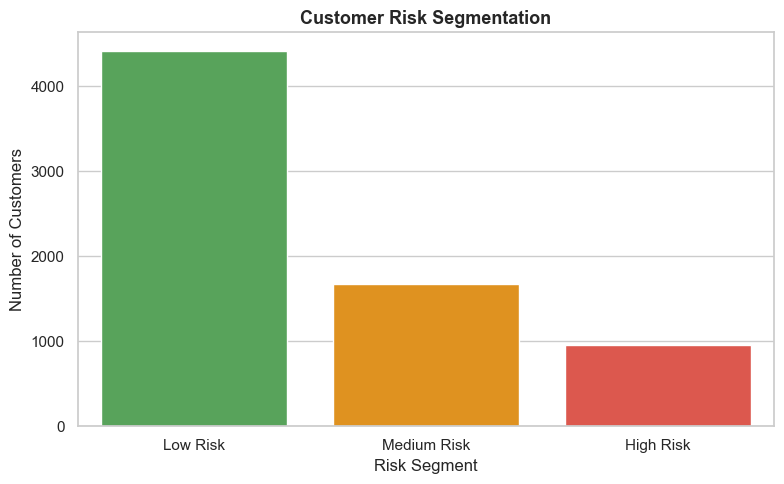

In [24]:
# Risk Segment Chart
risk_counts = df_results['RiskSegment'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=risk_counts.index, y=risk_counts.values,
            palette=['#4CAF50', '#FF9800', '#F44336'])
plt.title('Customer Risk Segmentation', fontweight='bold', fontsize=13)
plt.xlabel('Risk Segment')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'risk_segmentation.png'), dpi=150)
plt.show()

---
## STEP 15 — Export & Save

The final step is saving everything so the work can be used outside this notebook:
- **Predictions CSV:** Can be loaded into Power BI, Tableau, or sent to a CRM system
- **Saved model:** Can be loaded by another Python script and used to score new customers in production without retraining

In [25]:
# Export predictions
output_cols = ['Churn', 'ChurnProbability', 'ChurnPrediction', 'RiskSegment']
predictions_path = os.path.join(OUTPUT_PATH, 'churn_predictions.csv')
df_results[output_cols].to_csv(predictions_path, index=False)
print(f'✅ Predictions saved to: {predictions_path}')

# Save the best model and scaler
model_save_path  = os.path.join(MODEL_PATH, 'churn_model_gb.pkl')
scaler_save_path = os.path.join(MODEL_PATH, 'scaler.pkl')

joblib.dump(gb, model_save_path)
joblib.dump(scaler, scaler_save_path)
print(f'✅ Model saved to : {model_save_path}')
print(f'✅ Scaler saved to: {scaler_save_path}')
print('\n💡 To load the model later: gb = joblib.load("churn_model_gb.pkl")')

✅ Predictions saved to: C:\Users\Hamsa\OneDrive\Desktop\customer-churn-prediction-main\outputs\churn_predictions.csv
✅ Model saved to : C:\Users\Hamsa\OneDrive\Desktop\customer-churn-prediction-main\models\churn_model_gb.pkl
✅ Scaler saved to: C:\Users\Hamsa\OneDrive\Desktop\customer-churn-prediction-main\models\scaler.pkl

💡 To load the model later: gb = joblib.load("churn_model_gb.pkl")


In [26]:
import os
import joblib

model_path = os.path.join(BASE, "models", "churn_model_gb.pkl")

model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(model).__name__)

Model loaded successfully!
Model type: GradientBoostingClassifier


In [27]:
scaler_path = os.path.join(BASE, "models", "scaler.pkl")

scaler = joblib.load(scaler_path)

print("Scaler loaded successfully!")
print("Scaler type:", type(scaler).__name__)

Scaler loaded successfully!
Scaler type: StandardScaler


In [28]:
print("Model type:", type(model).__name__)

print("\nNumber of input features:", model.n_features_in_)

print("\nFeature names:")
print(getattr(model, "feature_names_in_", "Feature names not stored"))

Model type: GradientBoostingClassifier

Number of input features: 32

Feature names:
['SeniorCitizen' 'Partner' 'Dependents' 'tenure' 'PhoneService'
 'PaperlessBilling' 'MonthlyCharges' 'TotalCharges' 'gender_Male'
 'MultipleLines_No phone service' 'MultipleLines_Yes'
 'InternetService_Fiber optic' 'InternetService_No'
 'OnlineSecurity_No internet service' 'OnlineSecurity_Yes'
 'OnlineBackup_No internet service' 'OnlineBackup_Yes'
 'DeviceProtection_No internet service' 'DeviceProtection_Yes'
 'TechSupport_No internet service' 'TechSupport_Yes'
 'StreamingTV_No internet service' 'StreamingTV_Yes'
 'StreamingMovies_No internet service' 'StreamingMovies_Yes'
 'Contract_One year' 'Contract_Two year'
 'PaymentMethod_Credit card (automatic)' 'PaymentMethod_Electronic check'
 'PaymentMethod_Mailed check' 'AvgMonthlySpend' 'TenureGroup']


In [29]:
import os
import pandas as pd
import joblib

# Load the saved model
model = joblib.load(
    os.path.join(BASE, "models", "churn_model_gb.pkl")
)

# Find the dataset used by your project
print("Available data files:")
print(os.listdir(os.path.join(BASE, "data")))

Available data files:
['WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [30]:
import pandas as pd
import os

DATA_PATH = os.path.join(
    BASE, "data", "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [31]:
print("Cleaned data columns:")
print(df_clean.columns.tolist())

print("\nEncoded data shape:", df_encoded.shape)

print("\nModel expected features:", model.n_features_in_)
print("Model type:", type(model).__name__)

Cleaned data columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Encoded data shape: (7043, 33)

Model expected features: 32
Model type: GradientBoostingClassifier


In [32]:
print("Encoded columns:")
print(df_encoded.columns.tolist())

print("\nModel feature names:")
print(model.feature_names_in_.tolist())

Encoded columns:
['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn', 'gender_Male', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'AvgMonthlySpend', 'TenureGroup']

Model feature names:
['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'MultipleLines_No phone service', 'Mu

In [33]:

# Select one customer from the encoded dataset
# Remove Churn because it is the answer we want to predict
X = df_encoded.drop(columns=["Churn"])

# Match the exact feature order expected by the model
X = X.reindex(columns=model.feature_names_in_)

# Predict for the first customer
prediction = model.predict(X.iloc[[0]])[0]
probability = model.predict_proba(X.iloc[[0]])[0][1]

print("Customer churn prediction:", prediction)
print(f"Probability of churn: {probability:.2%}")


Customer churn prediction: 1
Probability of churn: 68.85%


In [34]:
# Predict churn for the first 5 customers
X_sample = X.iloc[:5]

predictions = model.predict(X_sample)
probabilities = model.predict_proba(X_sample)[:, 1]

results = pd.DataFrame({
    "Customer": range(1, 6),
    "Predicted_Churn": [
        "Yes" if p == 1 else "No" for p in predictions
    ],
    "Churn_Probability": (probabilities * 100).round(2)
})

display(results)

,Customer,Predicted_Churn,Churn_Probability
0,1,Yes,68.85
1,2,Yes,86.92
2,3,Yes,78.59
3,4,Yes,89.59
4,5,Yes,90.53


---
## Summary & Key Takeaways

### What we built
An end-to-end ML pipeline that predicts customer churn with ~85% ROC-AUC across 3 models.

### Key findings
- **Tenure** is the strongest predictor — new customers churn most
- **Month-to-month contracts** carry the highest churn risk
- **High monthly charges** significantly increase churn probability
- **Fiber optic** customers churn more than DSL customers

### Business recommendations
1. **Onboarding program** for customers in their first 12 months — highest risk window
2. **Contract upgrade incentives** for month-to-month customers flagged as High Risk
3. **Pricing review** for fiber optic plans — high charges + high churn = friction
4. **Monthly scoring** — run this model every month and feed High Risk list to the retention team

### What to explore next
- Hyperparameter tuning with GridSearchCV to improve model performance
- XGBoost or LightGBM for potentially higher accuracy
- SHAP values for deeper feature explanation
- Deploy the model as a REST API using Flask or FastAPI